# Module 06, Part 5: Quantization and QLoRA

This notebook is the runnable companion to Part 5 of the Module 06 learning content.
It checks, with code:

1. Absmax quantization by hand on four weights, at 8 bits and at 4 bits.
2. Why one outlier breaks a single shared scale, and how blocks of 64 fix it.
3. What a normal-float code is and how much it helps in a simple test.
4. QLoRA in miniature: a 4-bit base with a LoRA update on top, trained on the roll shift
   from Part 4.

The quantization here is **simulated**: weights are rounded to the codes and then
stored again as ordinary floats, so the accuracy effects are real but no memory is
saved by the code itself. The memory arithmetic is in Part 3.

In [1]:
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.15.0+cpu


## 1. Absmax quantization by hand

For $b$ bits, the scale is $s = \max|w| / (2^{b-1} - 1)$, the integer code is
$q = \text{round}(w / s)$, and the recovered weight is $w' = s q$.

In [2]:
import torch


def absmax_quantize(w, bits, block=None):
    """Quantize to signed integers with one scale per tensor, or per block of `block` weights.

    Returns (integer codes, scales, dequantized weights). s = max|w| / (2^(bits-1) - 1).
    """
    levels = 2 ** (bits - 1) - 1
    flat = w.reshape(-1)
    groups = flat.reshape(1, -1) if block is None else flat.reshape(-1, block)
    scales = groups.abs().amax(dim=1, keepdim=True) / levels
    scales = scales.clamp_min(1e-12)
    codes = torch.round(groups / scales).clamp(-levels, levels)
    deq = (codes * scales).reshape(w.shape)
    return codes.to(torch.int8).reshape(w.shape if block is None else (-1, block)), scales, deq


def normal_float_levels(bits=4):
    """2^bits levels at the quantiles of a standard normal, scaled so the largest is 1."""
    n = 2 ** bits
    probs = (torch.arange(n) + 0.5) / n
    levels = torch.distributions.Normal(0.0, 1.0).icdf(probs)
    return levels / levels.abs().max()


def normal_float_quantize(w, block=64, bits=4):
    """Simplified normal-float: one absmax scale per block, then the nearest of 16 normal-quantile levels."""
    levels = normal_float_levels(bits)
    groups = w.reshape(-1).reshape(-1, block)
    scales = groups.abs().amax(dim=1, keepdim=True).clamp_min(1e-12)
    idx = (groups / scales).unsqueeze(-1).sub(levels).abs().argmin(dim=-1)
    deq = (levels[idx] * scales).reshape(w.shape)
    return idx.to(torch.uint8), scales, deq


def relative_error(w, w_hat):
    return ((w - w_hat).norm() / w.norm()).item()

In [3]:
w = torch.tensor([0.12, -0.50, 0.03, 0.31])
for bits in (8, 4):
    codes, scales, deq = absmax_quantize(w, bits)
    print(f"{bits} bits: scale {scales.item():.5f}  codes {codes.flatten().tolist()}  recovered {[round(v, 3) for v in deq.tolist()]}")
    print(f"        largest error {(w - deq).abs().max().item():.4f}")

8 bits: scale 0.00394  codes [30, -127, 8, 79]  recovered [0.118, -0.5, 0.031, 0.311]
        largest error 0.0019
4 bits: scale 0.07143  codes [2, -7, 0, 4]  recovered [0.143, -0.5, 0.0, 0.286]
        largest error 0.0300


At 8 bits the integers are 30, -127, 8 and 79 and no weight is more than 0.002 off. At 4
bits the weight 0.03 has become exactly 0: fewer bits means fewer levels, and small
weights are the first to be lost.

## 2. Outliers, and why blocks help

The error of this scheme is set by the largest value in the group. One large weight
stretches the scale, and every other weight is then rounded onto a coarse grid. The
remedy is a scale per **block** of 64 weights, so one outlier damages only its own block.
The price is one extra 32-bit number per 64 weights, half a bit per weight.

First a direct picture: 4-bit quantization of 64 ordinary weights, with and without one
outlier 20 times the typical largest.

In [4]:
torch.manual_seed(1)
w64 = torch.randn(256) * 0.1
w_out = w64.clone(); w_out[10] = 20 * w64.abs().max()

for name, v in (("no outlier", w64), ("one outlier", w_out)):
    shared = absmax_quantize(v, 4)[2]
    blocks = absmax_quantize(v, 4, block=64)[2]
    others = torch.arange(256) != 10                       # error on every weight except the outlier itself
    err = lambda q: ((v - q)[others].norm() / v[others].norm()).item()
    print(f"{name:12s} relative error on the other 255 weights: one shared scale {err(shared):.3f}, blocks of 64 {err(blocks):.3f}")

no outlier   relative error on the other 255 weights: one shared scale 0.130, blocks of 64 0.118
one outlier  relative error on the other 255 weights: one shared scale 1.000, blocks of 64 0.494


With the outlier, a single shared scale rounds every ordinary weight to zero (error
1.000), while blocks of 64 confine the damage to the one block that holds the outlier,
so three of the four blocks are untouched and the error on the others is 0.494 instead.

### On a trained network

Quantize all three weight matrices of the Part 4 network (five seeds) with five schemes.
Report the relative error of the weights (the size of the difference divided by the size
of the original weights) and the accuracy on the held-out digits. Then repeat after
planting one outlier in each hidden layer: a weight 20 times the layer's largest.

The normal-float scheme here is a simplified version of the real format: 16 levels at
the quantiles of a normal distribution, scaled so the largest is 1, with one scale per
block of 64. Real NF4 differs in detail.

In [5]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SHIFTS = {
    "mild": lambda x: 0.6 * x + 0.2,
    "roll": lambda x: np.roll(x.reshape(-1, 8, 8), 1, axis=2).reshape(-1, 64),
    "invert": lambda x: 1.0 - x,
}


def load_data():
    """1,257 pretraining images and 540 held-out images (fixed split)."""
    d = load_digits()
    X, y = d.data / 16.0, d.target
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
    t = lambda a: torch.tensor(a, dtype=torch.float32)
    return t(Xtr), torch.tensor(ytr), t(Xte), torch.tensor(yte)


def make_mlp():
    return nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 10))


def accuracy(net, X, y):
    with torch.no_grad():
        return (net(X).argmax(1) == y).float().mean().item()


def pretrain(seed, data, steps=600, batch_size=64, lr=1e-3):
    Xtr, ytr, _, _ = data
    torch.manual_seed(seed)
    net = make_mlp()
    opt = torch.optim.Adam(net.parameters(), lr)
    g = torch.Generator().manual_seed(seed)
    for _ in range(steps):
        i = torch.randint(0, len(Xtr), (batch_size,), generator=g)
        loss = nn.functional.cross_entropy(net(Xtr[i]), ytr[i])
        opt.zero_grad(); loss.backward(); opt.step()
    return net


def shifted_split(data, shift, n_adapt=100):
    """Shift the held-out images; the first n_adapt are for adaptation, the rest for evaluation."""
    _, _, Xte, yte = data
    Xs = torch.tensor(SHIFTS[shift](Xte.numpy()), dtype=torch.float32)
    return Xs[:n_adapt], yte[:n_adapt], Xs[n_adapt:], yte[n_adapt:]


def adapt(net, Xa, ya, params, steps=300, lr=1e-3):
    """Full-batch Adam on the given parameters only. Returns the (modified) network."""
    opt = torch.optim.Adam(params, lr)
    for _ in range(steps):
        loss = nn.functional.cross_entropy(net(Xa), ya)
        opt.zero_grad(); loss.backward(); opt.step()
    return net

In [6]:
data = load_data()
Xte, yte = data[2], data[3]
schemes = {
    "Full precision": None,
    "int8, whole tensor": lambda w: absmax_quantize(w, 8)[2],
    "int8, blocks of 64": lambda w: absmax_quantize(w, 8, 64)[2],
    "4-bit, whole tensor": lambda w: absmax_quantize(w, 4)[2],
    "4-bit, blocks of 64": lambda w: absmax_quantize(w, 4, 64)[2],
    "4-bit normal-float, blocks of 64": lambda w: normal_float_quantize(w, 64)[2],
}
linears = lambda net: [m for m in net if isinstance(m, nn.Linear)]

results = {}
for seed in range(5):
    base = pretrain(seed, data)
    for outlier in (False, True):
        net0 = copy.deepcopy(base)
        if outlier:
            with torch.no_grad():
                for layer in linears(net0)[:2]:                       # the two hidden layers
                    layer.weight.view(-1)[7] = 20 * layer.weight.abs().max()
        for name, fn in schemes.items():
            net = copy.deepcopy(net0)
            num = den = 0.0
            for layer in linears(net):
                if fn is not None:
                    q = fn(layer.weight.detach())
                    num += (layer.weight.detach() - q).pow(2).sum().item()
                    den += layer.weight.detach().pow(2).sum().item()
                    layer.weight.data = q
            err = (num / den) ** 0.5 if fn is not None else 0.0
            results.setdefault((outlier, name), []).append((err, accuracy(net, Xte, yte)))

print(f"{'scheme':34s}{'error':>8s}{'accuracy':>10s}{'error':>10s}{'accuracy':>10s}")
print(f"{'':34s}{'--- trained weights ---':>18s}{'--- with outliers ---':>20s}")
for name in schemes:
    a, b = np.mean(results[(False, name)], 0), np.mean(results[(True, name)], 0)
    print(f"{name:34s}{a[0]:8.3f}{a[1]:10.3f}{b[0]:10.3f}{b[1]:10.3f}")

scheme                               error  accuracy     error  accuracy
                                  --- trained weights ------ with outliers ---
Full precision                       0.000     0.975     0.000     0.975
int8, whole tensor                   0.011     0.974     0.189     0.976
int8, blocks of 64                   0.006     0.975     0.009     0.975
4-bit, whole tensor                  0.191     0.975     0.891     0.099
4-bit, blocks of 64                  0.100     0.974     0.100     0.973
4-bit normal-float, blocks of 64     0.091     0.976     0.137     0.972


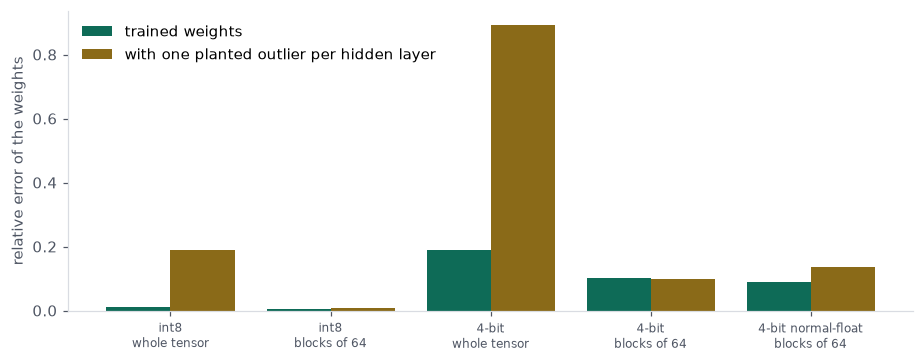

In [7]:
names = list(schemes)[1:]
clean = [np.mean(results[(False, n)], 0)[0] for n in names]
dirty = [np.mean(results[(True, n)], 0)[0] for n in names]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
x = np.arange(len(names))
ax.bar(x - 0.2, clean, 0.4, color=GREEN, label="trained weights")
ax.bar(x + 0.2, dirty, 0.4, color=AMBER, label="with one planted outlier per hidden layer")
ax.set_xticks(x); ax.set_xticklabels([n.replace(", ", "\n") for n in names], fontsize=8)
ax.set_ylabel("relative error of the weights"); ax.legend(frameon=False); ax.grid(False)
plt.tight_layout(); plt.show()

Four readings.

- **Eight bits lose nothing measurable.** Every 8-bit row is within 0.002 of the
  full-precision accuracy of 0.975, with or without outliers. The whole-tensor int8 scale
  is stretched by the outlier (error 0.190) and the network still copes, because 255
  levels are enough to keep the signal.
- **4 bits with one scale per tensor looks fine and then collapses.** On trained weights
  it scores 0.976. With one outlier per hidden layer it scores 0.099, which is chance for
  ten classes, even though the same outlier does not hurt the unquantized network at all.
- **Blocks of 64 fix it.** The 4-bit blockwise network keeps 0.974 with the outliers in
  place. The cost is half a bit per weight for the scales.
- **Normal-float spacing helps only a little in this test.** It has slightly less error
  than evenly spaced 4-bit levels on trained weights (0.091 against 0.100) and more
  with the outliers (0.138 against 0.100). Accuracy differences of a few thousandths
  between the 4-bit block schemes are within noise.

This is a very small network, and a planted outlier is an artificial stand-in for the
large weights and activations that real language models are known to have. A 4-bit
model keeping its accuracy here is no guarantee that a given large model will. What the
experiment does show is the mechanism: the scale, and whether it is shared too widely,
decides whether 4 bits work.

## 3. QLoRA in miniature

Quantization alone has a problem for fine-tuning: a weight stored as a 4-bit integer
cannot be trained, because rounding has no useful gradient. QLoRA never trains the base.
The frozen base is stored in 4 bits, the LoRA matrices stay in full precision, each
layer's weights are converted back just before use, and gradients flow through that
converted copy into $A$ and $B$, the only things updated.

Here: take the pretrained network, replace its weights with the normal-float
quantized version (the base), add rank-16 LoRA on the two hidden layers, and adapt to the
roll shift from Part 4 exactly as before. Compare with LoRA on the original base.

In [8]:
import math

import torch
import torch.nn as nn


class LoRALinear(nn.Module):
    """Wrap a frozen nn.Linear and add the low-rank update (alpha / r) * B A.

    A is (r, in_features), random. B is (out_features, r), zero. So the layer
    starts exactly equal to the wrapped layer.
    """

    def __init__(self, base, r, alpha=None, zero_B=True):
        super().__init__()
        self.base, self.r = base, r
        self.alpha = alpha if alpha is not None else r
        for p in self.base.parameters():
            p.requires_grad_(False)
        self.A = nn.Parameter(torch.empty(r, base.in_features))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r) if zero_B
                              else torch.randn(base.out_features, r) * 0.01)
        self.scale = self.alpha / r

    def forward(self, x):
        return self.base(x) + self.scale * (x @ self.A.T) @ self.B.T

    @torch.no_grad()
    def merged(self):
        """A single nn.Linear holding W + (alpha / r) B A, with no extra cost at inference."""
        out = nn.Linear(self.base.in_features, self.base.out_features)
        out.weight.copy_(self.base.weight + self.scale * self.B @ self.A)
        out.bias.copy_(self.base.bias)
        return out


def add_lora(mlp, r, alpha=None):
    """Replace the hidden Linear layers of a Sequential MLP with LoRA layers.

    The last Linear (the head) stays frozen and unwrapped. Returns a new Sequential;
    the original is not modified.
    """
    import copy
    net = copy.deepcopy(mlp)
    linears = [i for i, m in enumerate(net) if isinstance(m, nn.Linear)]
    for i in linears[:-1]:
        net[i] = LoRALinear(net[i], r, alpha)
    for p in net[linears[-1]].parameters():
        p.requires_grad_(False)
    return net


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [9]:
Xa, ya, Xe, ye = shifted_split(data, "roll")
rows = {"no adaptation, 16-bit base": [], "no adaptation, quantized base": [],
        "LoRA r=16 on the 16-bit base": [], "QLoRA r=16 on the quantized base": []}
for seed in range(5):
    base = pretrain(seed, data)
    qbase = copy.deepcopy(base)
    for layer in linears(qbase):
        layer.weight.data = normal_float_quantize(layer.weight.detach(), 64)[2]
    rows["no adaptation, 16-bit base"].append(accuracy(base, Xe, ye))
    rows["no adaptation, quantized base"].append(accuracy(qbase, Xe, ye))
    for key, b in (("LoRA r=16 on the 16-bit base", base), ("QLoRA r=16 on the quantized base", qbase)):
        torch.manual_seed(seed)
        net = add_lora(b, 16, alpha=32)
        adapt(net, Xa, ya, [p for p in net.parameters() if p.requires_grad], lr=3e-3)
        rows[key].append(accuracy(net, Xe, ye))

print("Roll shift, mean accuracy over 5 seeds")
for k, v in rows.items():
    print(f"  {k:34s}{np.mean(v):.3f}")
print("trainable parameters in the LoRA layers:", f"{count_trainable(add_lora(make_mlp(), 16)):,}")

Roll shift, mean accuracy over 5 seeds
  no adaptation, 16-bit base        0.468
  no adaptation, quantized base     0.468
  LoRA r=16 on the 16-bit base      0.864
  QLoRA r=16 on the quantized base  0.868
trainable parameters in the LoRA layers: 13,312


The adapted quantized model reaches 0.867 against 0.864 for LoRA on the original weights,
a difference well inside the seed-to-seed spread, so in this miniature QLoRA matched
LoRA. Notice also that quantizing the base barely changed the unadapted network (0.468
against 0.469), so this test is gentle. Published QLoRA results on large language models
report quality close to a 16-bit LoRA run, but whether that holds for your model and your
task is something to measure, not assume.

The memory consequence for a model with 7 billion parameters is in Part 3: about 112 GB
for full fine-tuning, 14.3 GB for LoRA on a 16-bit base and 4.2 GB for QLoRA. What QLoRA
costs is worth stating: the base carries quantization error, each step is somewhat slower
because every weight has to be converted back before use, and everything LoRA gives up
in Part 4 still applies.

## Try it

1. Implement 8-bit and 4-bit absmax quantization yourself and check that you get the
   integers in section 1 for the four weights.
2. In section 2, use blocks of 16 and of 256 instead of 64. How do the error and the
   half-bit overhead trade off?
3. Plant an outlier 100 times the largest weight instead of 20. Which schemes still hold?
4. In section 3, quantize to 4 bits with blocks of 64 using `absmax_quantize` instead of
   the normal-float code. Does the QLoRA result change?
5. Estimate the training memory of a model of your choice under full fine-tuning, LoRA
   and QLoRA, and say which of the three fits on a 16 GB GPU.

## What this notebook showed

- Quantization stores each weight in fewer bits plus a scale. Small weights are the
  first casualty of fewer bits.
- The scale decides whether 4 bits work. A single scale shared across a tensor is
  fragile to one outlier, and a scale per block of 64 is not.
- QLoRA freezes a quantized base and trains a 16-bit LoRA on top. In this miniature the
  adapted quantized model matched LoRA on the original weights.
- Every efficiency technique trades something for memory. Measure what, on your model
  and your task.